In [2]:
from pathlib import Path
import pandas as pd

# Load processed dataset (works from project root or notebooks/)
candidates = [
    Path("data/processed/global_ads_performance_dataset_processed.csv"),
    Path("../data/processed/global_ads_performance_dataset_processed.csv"),
]

csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Could not find processed CSV. Tried: " + ", ".join(str(p) for p in candidates)
    )

df = pd.read_csv(csv_path)

mean_cpc_per_platform = (
    df.groupby("platform", as_index=False)["CPC"]
    .mean()
    .rename(columns={"CPC": "mean_CPC"})
    .sort_values("mean_CPC", ascending=False)
)

print("Loaded from:", csv_path.resolve())
mean_cpc_per_platform

Loaded from: /Users/Carys/Documents/Github/ads-analysis/data/processed/global_ads_performance_dataset_processed.csv


,platform,mean_CPC
0,Google Ads,2.149069
1,Meta Ads,1.316095
2,TikTok Ads,1.009978


In [2]:
mean_cpa_per_platform = (
    df.groupby("platform", as_index=False)["CPA"]
    .mean()
    .rename(columns={"CPA": "mean_CPA"})
    .sort_values("mean_CPA", ascending=False)
)

mean_cpa_per_platform

,platform,mean_CPA
0,Google Ads,64.064653
1,Meta Ads,39.096921
2,TikTok Ads,29.196711


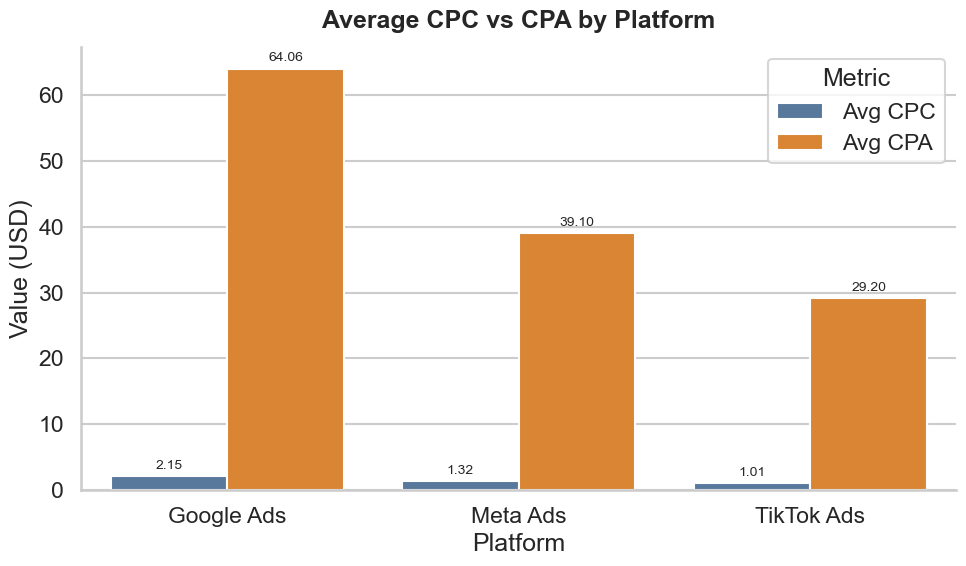

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Build a single table with both metrics
platform_metrics = (
    df.groupby("platform", as_index=False)
    .agg(avg_CPC=("CPC", "mean"), avg_CPA=("CPA", "mean"))
    .sort_values("avg_CPA", ascending=False)
)

plot_df = platform_metrics.melt(
    id_vars="platform",
    value_vars=["avg_CPC", "avg_CPA"],
    var_name="metric",
    value_name="value",
)

metric_labels = {"avg_CPC": "Avg CPC", "avg_CPA": "Avg CPA"}
plot_df["metric"] = plot_df["metric"].map(metric_labels)

sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=plot_df,
    x="platform",
    y="value",
    hue="metric",
    palette={"Avg CPC": "#4C78A8", "Avg CPA": "#F58518"},
)

ax.set_title("Average CPC vs CPA by Platform", pad=14, weight="bold")
ax.set_xlabel("Platform")
ax.set_ylabel("Value (USD)")
ax.legend(title="Metric", frameon=True)

# Add value labels for readability
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=10)

sns.despine(left=False, bottom=False)
plt.tight_layout()
plt.show()

In [3]:
# Save average CPC/CPA by platform to its own CSV
avg_platform_metrics = (
    df.groupby("platform", as_index=False)
    .agg(avg_CPC=("CPC", "mean"), avg_CPA=("CPA", "mean"))
    .sort_values("platform")
)

processed_candidates = [Path("data/processed"), Path("../data/processed")]
processed_dir = next((p for p in processed_candidates if p.parent.exists()), processed_candidates[0])
processed_dir.mkdir(parents=True, exist_ok=True)

output_path = processed_dir / "platform_avg_cpc_cpa.csv"
avg_platform_metrics.to_csv(output_path, index=False)

print("Saved:", output_path.resolve())
avg_platform_metrics

Saved: /Users/Carys/Documents/Github/ads-analysis/data/processed/platform_avg_cpc_cpa.csv


,platform,avg_CPC,avg_CPA
0,Google Ads,2.149069,64.064653
1,Meta Ads,1.316095,39.096921
2,TikTok Ads,1.009978,29.196711


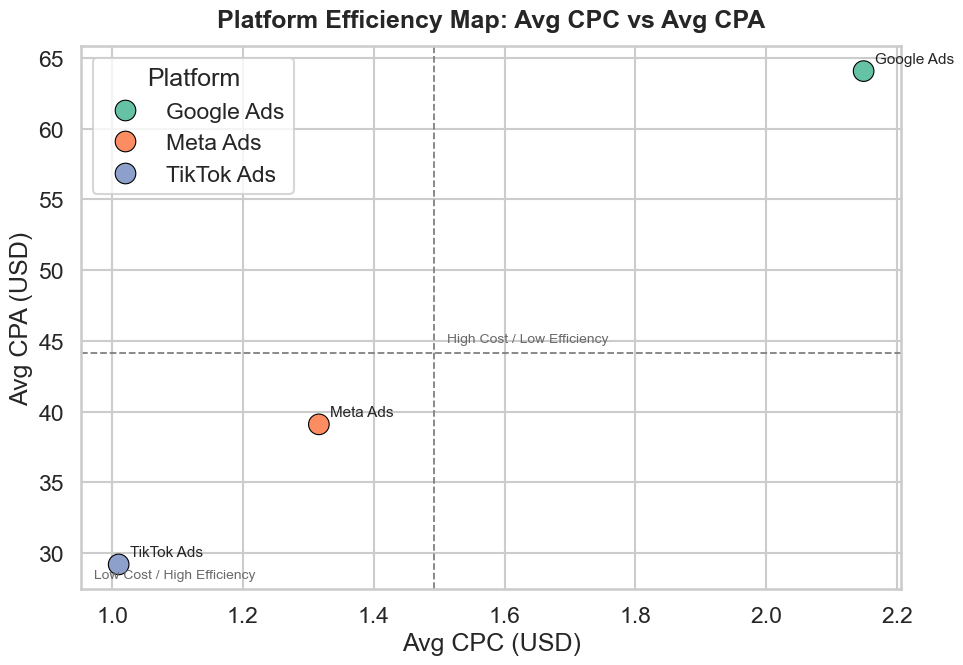

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Recompute metrics in this cell so plotting works regardless of run order
scatter_df = (
    df.groupby("platform", as_index=False)
    .agg(avg_CPC=("CPC", "mean"), avg_CPA=("CPA", "mean"))
    .sort_values("avg_CPA", ascending=False)
)

x_mid = scatter_df["avg_CPC"].mean()
y_mid = scatter_df["avg_CPA"].mean()

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=scatter_df,
    x="avg_CPC",
    y="avg_CPA",
    hue="platform",
    s=220,
    palette="Set2",
    edgecolor="black",
    linewidth=0.8,
    ax=ax,
)

for _, row in scatter_df.iterrows():
    ax.annotate(
        row["platform"],
        (row["avg_CPC"], row["avg_CPA"]),
        xytext=(8, 6),
        textcoords="offset points",
        fontsize=11,
    )

# Mean lines split the chart into quadrants
ax.axvline(x_mid, color="gray", linestyle="--", linewidth=1.3)
ax.axhline(y_mid, color="gray", linestyle="--", linewidth=1.3)

ax.set_title("Platform Efficiency Map: Avg CPC vs Avg CPA", pad=14, weight="bold")
ax.set_xlabel("Avg CPC (USD)")
ax.set_ylabel("Avg CPA (USD)")

ax.text(x_mid + 0.02, y_mid + 0.8, "High Cost / Low Efficiency", fontsize=10, color="dimgray")
ax.text(ax.get_xlim()[0] + 0.02, ax.get_ylim()[0] + 0.8, "Low Cost / High Efficiency", fontsize=10, color="dimgray")

ax.legend(title="Platform", frameon=True, loc="best")
plt.tight_layout()
plt.show()